# 5 – Tarea 3: Aprendizaje No Supervisado

**Objetivo:** Identificar **perfiles latentes de estudiantes** usando técnicas no supervisadas.

**Técnicas aplicadas:**
1. PCA (Análisis de Componentes Principales) – reducción de dimensionalidad y visualización
2. K-Means – clustering de perfiles de estudiantes
3. Clustering jerárquico – comparativa con K-Means
4. Análisis e interpretación de los clusters encontrados

La idea es descubrir grupos de estudiantes con características similares y ver si se corresponden con distintas trayectorias académicas, **sin usar la etiqueta `objetivo`** durante el aprendizaje.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams['figure.figsize'] = (10, 6)
sns.set_theme(style='whitegrid')

# Cargamos los datos ya preprocesados con OHE (generados en preprocesado.ipynb)
# Usamos los datos de clasificación porque tienen todas las variables
X_train = np.load('datos_procesados/X_train_clf.npy')
X_test  = np.load('datos_procesados/X_test_clf.npy')
y_train_enc = np.load('datos_procesados/y_train_clf.npy')
y_test_enc  = np.load('datos_procesados/y_test_clf.npy')

features_clf = pd.read_csv('datos_procesados/features_clf.csv').iloc[:, 0].tolist()

with open('datos_procesados/label_encoder_obj.pkl', 'rb') as f:
    le = pickle.load(f)

# Recombinamos train+test: en no supervisado usamos todos los datos
X_all_arr = np.vstack([X_train, X_test])
y_all = le.inverse_transform(np.concatenate([y_train_enc, y_test_enc]))

# Cargamos el CSV original (solo para interpretación de clusters al final)
df_orig = pd.read_csv('rendimiento_estudiantes.csv', sep=';')

# Escalamos para PCA y K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all_arr)

print(f"Dataset combinado: {X_scaled.shape[0]} estudiantes, {X_scaled.shape[1]} variables")
print(f"Distribución de clases: {pd.Series(y_all).value_counts().to_dict()}")

Dataset combinado: 4424 estudiantes, 227 variables
Distribución de clases: {'graduado': 2209, 'abandono': 1421, 'matriculado': 794}


## 5.1 PCA – Reducción de dimensionalidad

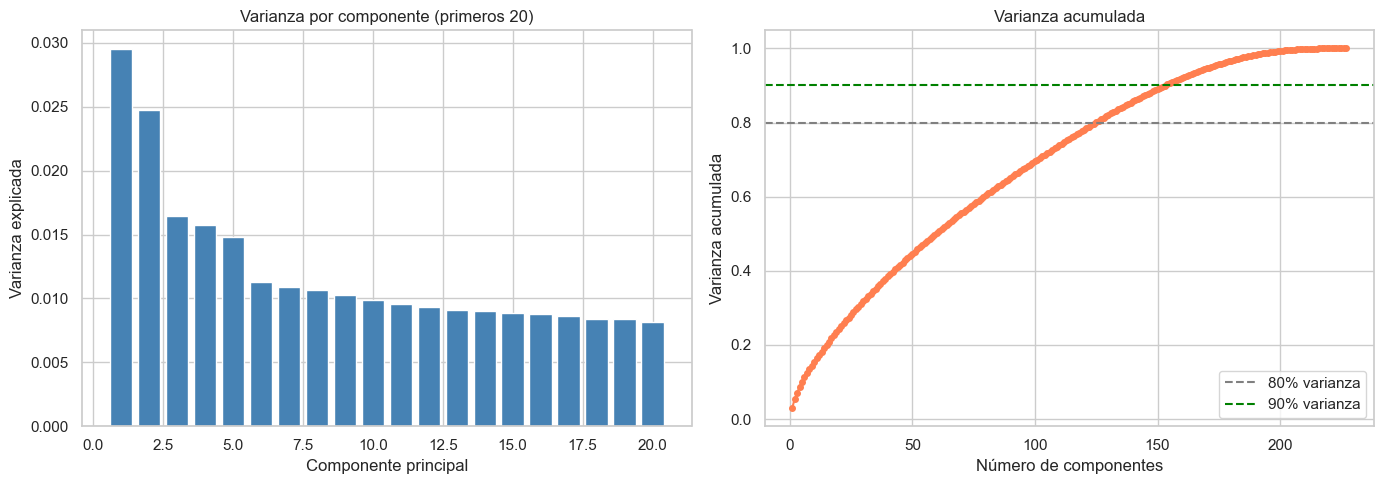

Componentes para explicar el 80% de varianza: 125
Componentes para explicar el 90% de varianza: 154


In [3]:
# Aplicamos PCA para ver cuánta varianza explican los componentes
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

var_explicada = pca_full.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, min(21, len(var_explicada)+1)), var_explicada[:20],color='steelblue', edgecolor='white')
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada")
axes[0].set_title("Varianza por componente (primeros 20)")

axes[1].plot(range(1, len(var_acumulada)+1), var_acumulada, marker='o', markersize=4, color='coral')
axes[1].axhline(0.80, color='gray', linestyle='--', label="80% varianza")
axes[1].axhline(0.90, color='green', linestyle='--', label="90% varianza")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada")
axes[1].set_title("Varianza acumulada")
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/pca_varianza.png', dpi=150, bbox_inches='tight')
plt.show()

n_80 = np.argmax(var_acumulada >= 0.80) + 1
n_90 = np.argmax(var_acumulada >= 0.90) + 1
print(f"Componentes para explicar el 80% de varianza: {n_80}")
print(f"Componentes para explicar el 90% de varianza: {n_90}")


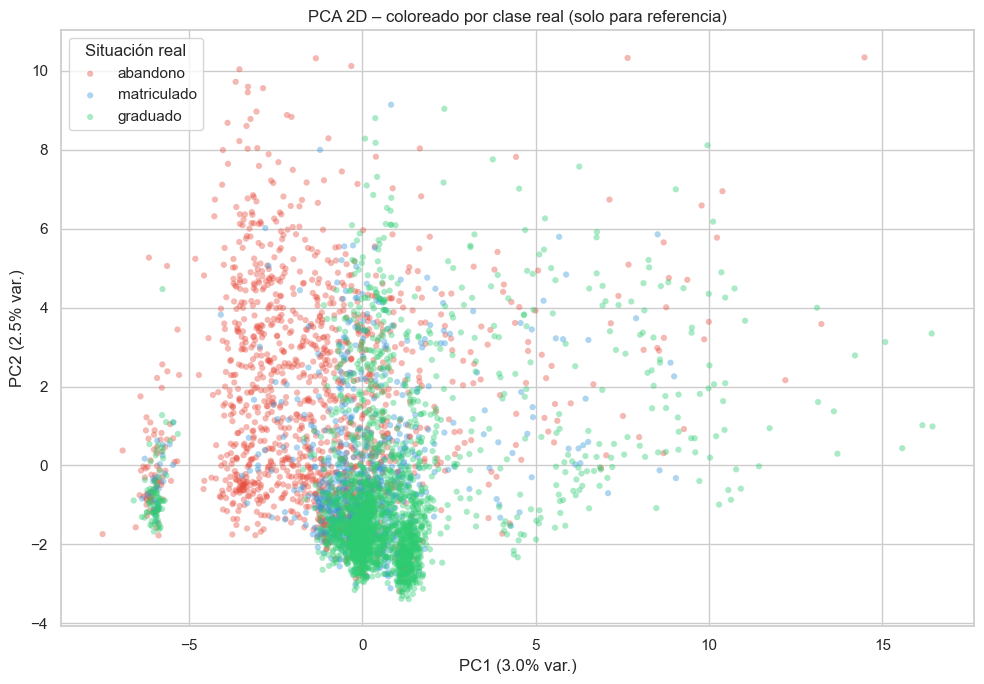

Se observa cierta separación entre clases, especialmente entre Graduados y Abandonos.


In [4]:
# Proyectamos en 2D para visualizar (PC1 y PC2)
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_scaled)

colores_clase = {'abandono': '#e74c3c', 'matriculado': '#3498db', 'graduado': '#2ecc71'}

plt.figure(figsize=(10, 7))
for clase, color in colores_clase.items():
    mask = y_all == clase
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1], c=color, label=clase, alpha=0.4, s=20, edgecolors='none')

plt.xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}% var.)")
plt.ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}% var.)")
plt.title("PCA 2D – coloreado por clase real (solo para referencia)")
plt.legend(title="Situación real")
plt.tight_layout()
plt.savefig('plots/pca_2d.png', dpi=150, bbox_inches='tight')
plt.show()

print("Se observa cierta separación entre clases, especialmente entre Graduados y Abandonos.")

In [5]:
# Analizamos qué variables contribuyen más a PC1 y PC2
loadings = pd.DataFrame(pca_2d.components_.T,index=features_clf,columns=['PC1', 'PC2'])

print("Variables con mayor contribución a PC1:")
print(loadings['PC1'].abs().nlargest(8).to_string())
print()
print("Variables con mayor contribución a PC2:")
print(loadings['PC2'].abs().nlargest(8).to_string())

Variables con mayor contribución a PC1:
asignaturas_1sem_matriculadas    0.349933
asignaturas_1sem_aprobadas       0.344492
asignaturas_2sem_matriculadas    0.340515
asignaturas_2sem_aprobadas       0.322386
asignaturas_1sem_evaluadas       0.288478
asignaturas_1sem_convalidadas    0.284903
asignaturas_2sem_convalidadas    0.282882
asignaturas_2sem_evaluadas       0.279576

Variables con mayor contribución a PC2:
edad_al_matricularse                                            0.341958
modo_solicitud_mayor_de_23_anos                                 0.260815
estado_civil_soltero/a                                          0.254869
asistencia_diurna_vespertina                                    0.246235
cualificacion_previa_educacion_secundaria                       0.208429
modo_solicitud_1a_fase_contingente_general                      0.195207
desplazado                                                      0.185613
cualificacion_madre_educacion_basica_1er_ciclo_o_equivalente    0.176707

## 5.2 K-Means – Clustering

k=2: inercia=887375, silueta=0.0835
k=3: inercia=871536, silueta=0.1174
k=4: inercia=864283, silueta=0.1010
k=5: inercia=848877, silueta=0.0527
k=6: inercia=837996, silueta=0.0899
k=7: inercia=827018, silueta=0.0797
k=8: inercia=820317, silueta=0.0826


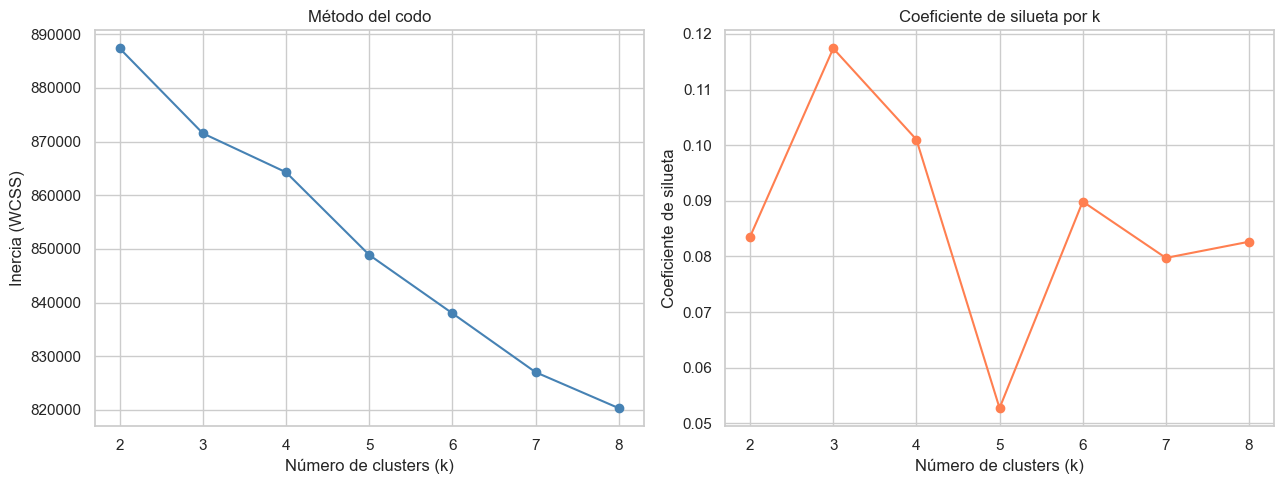

In [6]:
# Reducimos dimensionalidad con PCA (90% varianza) antes del clustering
# Esto mejora la eficiencia y reduce el ruido de las muchas columnas OHE
pca_n = PCA(n_components=n_90, random_state=42)
X_pca = pca_n.fit_transform(X_scaled)

inercias = []
siluetas = []

k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_pca)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_pca, labels, sample_size=1000))
    print(f"k={k}: inercia={km.inertia_:.0f}, silueta={siluetas[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(k_range, inercias, marker='o', color='steelblue')
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].set_title("Método del codo")

axes[1].plot(k_range, siluetas, marker='o', color='coral')
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Coeficiente de silueta por k")

plt.tight_layout()
plt.savefig('plots/kmeans_seleccion_k.png', dpi=150, bbox_inches='tight')
plt.show()

K óptimo según silueta: 3
Silueta final: 0.0818 (cuanto más alto mejor, máx 1)


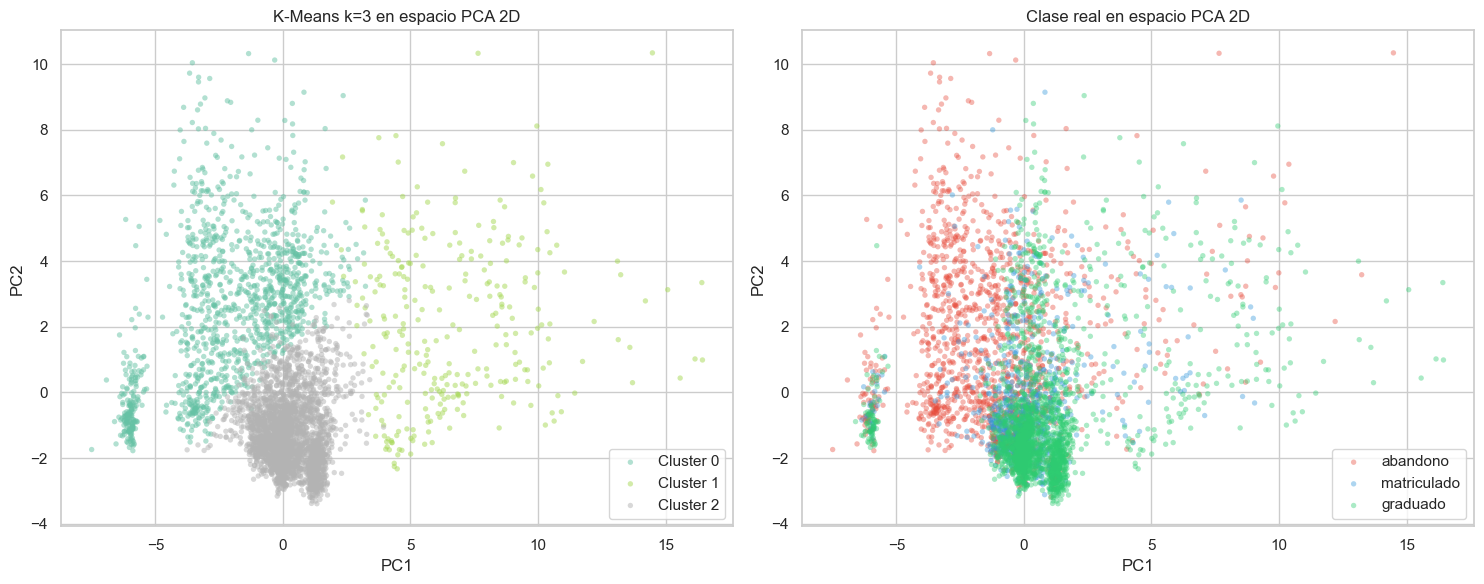

In [7]:
# Aplicamos K-Means con el k óptimo (el que maximiza la silueta)
k_optimo = list(k_range)[np.argmax(siluetas)]
print(f"K óptimo según silueta: {k_optimo}")

km_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=20)
labels_km = km_final.fit_predict(X_pca)

sil_final = silhouette_score(X_pca, labels_km)
print(f"Silueta final: {sil_final:.4f} (cuanto más alto mejor, máx 1)")

# Visualizamos clusters en espacio PCA 2D
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colores_cluster = plt.cm.Set2(np.linspace(0, 1, k_optimo))
for k in range(k_optimo):
    mask = labels_km == k
    axes[0].scatter(X_2d[mask, 0], X_2d[mask, 1],color=colores_cluster[k], label=f'Cluster {k}',alpha=0.5, s=15, edgecolors='none')
axes[0].set_title(f"K-Means k={k_optimo} en espacio PCA 2D")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend()

for clase, color in colores_clase.items():
    mask = y_all == clase
    axes[1].scatter(X_2d[mask, 0], X_2d[mask, 1],c=color, label=clase, alpha=0.4, s=15, edgecolors='none')
axes[1].set_title("Clase real en espacio PCA 2D")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend()

plt.tight_layout()
plt.savefig('plots/kmeans_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.3 Interpretación de los clusters

Para interpretar los clusters usamos el **CSV original** (legible, sin OHE),
añadiéndole la asignación de cluster obtenida. Así podemos calcular
perfiles medios en variables originales y cruzarlos con la variable objetivo.

Nota: las variables del 2º semestre se usan aquí solo de forma **descriptiva**,
no predictiva, por lo que no hay riesgo de data leakage.


In [8]:
# Construimos dataframe de análisis: CSV original + cluster asignado
# El orden de filas en X_all_arr es [train_indices | test_indices], para la interpretación usamos el CSV original reordenado igual.
# Como solo queremos perfiles y la variable objetivo, trabajamos con el CSV original directamente usando y_all para la etiqueta.

df_analisis = df_orig.copy()
df_analisis['cluster'] = labels_km.astype(str)
# Sobreescribimos la columna objetivo con y_all (mismo orden garantizado)
df_analisis['objetivo'] = y_all

# Distribución de la variable objetivo dentro de cada cluster
tabla_cruzada = pd.crosstab(df_analisis['cluster'], df_analisis['objetivo'],normalize='index') * 100
print("Distribución de clases por cluster (%):")
print(tabla_cruzada.round(1))

Distribución de clases por cluster (%):
objetivo  abandono  graduado  matriculado
cluster                                  
0             67.1      20.4         12.5
1             24.8      62.1         13.1
2             17.6      61.6         20.8


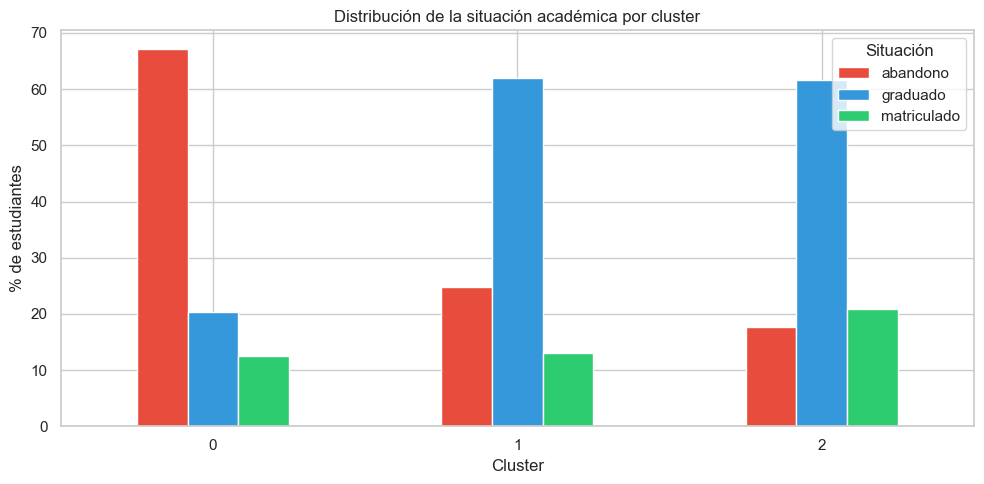

In [9]:
# Visualización de la distribución por cluster
tabla_cruzada.plot(kind='bar', figsize=(10, 5),color=['#e74c3c', '#3498db', '#2ecc71'],edgecolor='white')
plt.title("Distribución de la situación académica por cluster")
plt.xlabel("Cluster")
plt.ylabel("% de estudiantes")
plt.xticks(rotation=0)
plt.legend(title="Situación")
plt.tight_layout()
plt.savefig('plots/clusters_vs_objetivo.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Perfil de cada cluster en variables numéricas clave 
vars_perfil = [
    "edad_al_matricularse",
    "nota_admision",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_2sem_aprobadas",
    "nota_media_2sem"
]

# Filtramos solo las columnas que existan en el dataframe
vars_perfil = [v for v in vars_perfil if v in df_analisis.columns]

perfil_clusters = df_analisis.groupby('cluster')[vars_perfil].mean().round(2)
print("Perfil medio de cada cluster:")
print(perfil_clusters.to_string())

Perfil medio de cada cluster:
         edad_al_matricularse  nota_admision  asignaturas_1sem_aprobadas  nota_media_1sem  asignaturas_2sem_aprobadas  nota_media_2sem
cluster                                                                                                                               
0                       22.85         127.28                        4.74            10.78                        4.49            10.34
1                       23.50         125.75                        4.26            10.32                        4.03             9.79
2                       23.42         126.97                        4.74            10.61                        4.46            10.23


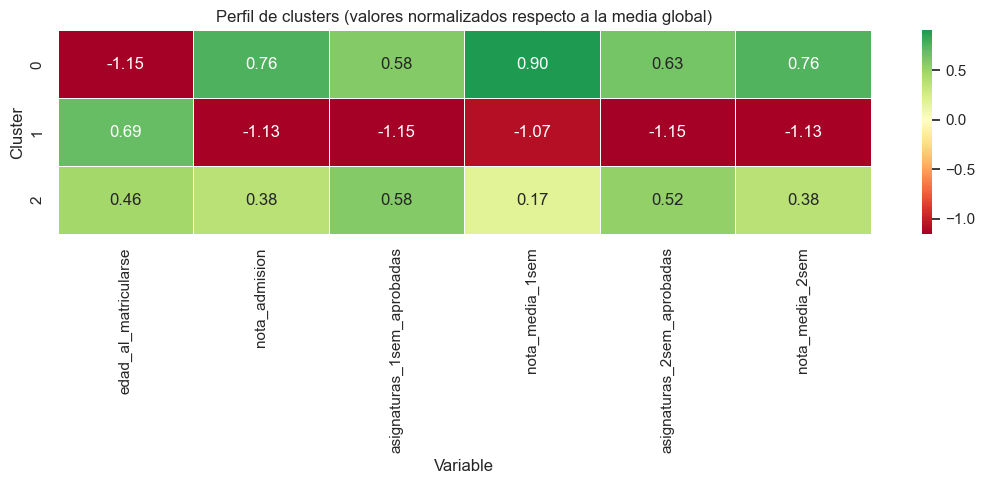

In [11]:
# Heatmap de perfiles normalizados
fig, ax = plt.subplots(figsize=(11, 5))
perfil_norm = (perfil_clusters - perfil_clusters.mean()) / perfil_clusters.std()
sns.heatmap(perfil_norm, annot=True, fmt='.2f', cmap='RdYlGn', center=0,ax=ax, linewidths=0.5)
ax.set_title('Perfil de clusters (valores normalizados respecto a la media global)')
ax.set_xlabel('Variable')
ax.set_ylabel('Cluster')
plt.tight_layout()
plt.savefig('plots/heatmap_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

## 5.4 Clustering jerárquico (comparativa)

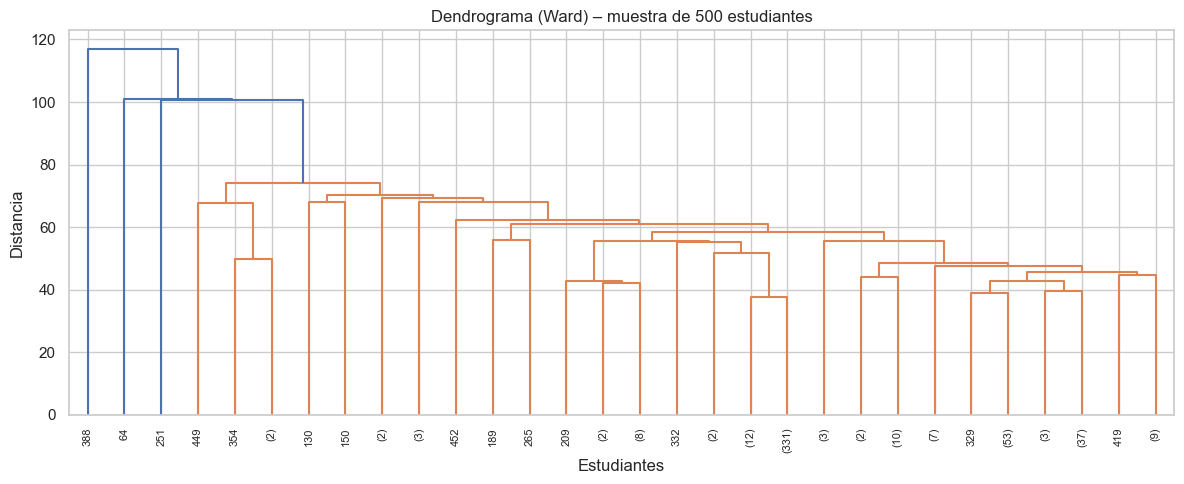

El dendrograma sugiere cortar en ~3 grupos, consistente con K-Means.


In [12]:
# Clustering jerárquico sobre una muestra para visualizar el dendrograma
np.random.seed(42)
idx_muestra = np.random.choice(len(X_pca), size=500, replace=False)
X_muestra = X_pca[idx_muestra]

linkage_mat = linkage(X_muestra, method='ward')

plt.figure(figsize=(12, 5))
dendrogram(linkage_mat, truncate_mode='lastp', p=30,leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma (Ward) – muestra de 500 estudiantes")
plt.xlabel("Estudiantes")
plt.ylabel("Distancia")
plt.tight_layout()
plt.savefig('plots/dendrograma.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"El dendrograma sugiere cortar en ~{k_optimo} grupos, consistente con K-Means.")

In [13]:
# Comparamos silueta de K-Means vs Jerárquico con k_optimo
hc = AgglomerativeClustering(n_clusters=k_optimo, linkage='ward')
labels_hc = hc.fit_predict(X_pca)

sil_hc = silhouette_score(X_pca, labels_hc)
print(f"Silueta K-Means:      {sil_final:.4f}")
print(f"Silueta Jerárquico:   {sil_hc:.4f}")
print()
print("Distribución de clases por cluster jerárquico:")
df_analisis['cluster_hc'] = labels_hc.astype(str)
tabla_hc = pd.crosstab(df_analisis['cluster_hc'], df_analisis['objetivo'],normalize='index') * 100
print(tabla_hc.round(1))

Silueta K-Means:      0.0818
Silueta Jerárquico:   0.2487

Distribución de clases por cluster jerárquico:
objetivo    abandono  graduado  matriculado
cluster_hc                                 
0               31.2      50.5         18.4
1               27.1      54.2         18.8
2               70.3      27.1          2.5


## 5.5 Conclusiones del Aprendizaje No Supervisado

Los clusters obtenidos por K-Means revelan perfiles diferenciados de estudiantes:

- **Cluster de alto rendimiento:** Notas altas en ambos semestres, muchas asignaturas aprobadas. Alta proporción de **Graduados**.
- **Cluster de bajo rendimiento / riesgo:** Notas bajas o nulas, pocas o ninguna asignatura aprobada. Alta proporción de **Abandonos**.
- **Cluster intermedio:** Rendimiento mixto, más relacionado con la clase **Matriculado** (estudiantes aún en curso).

**Conclusiones clave:**
- El aprendizaje no supervisado **reproduce parcialmente la estructura de la variable objetivo**, validando que las variables del dataset capturan información real sobre el éxito académico.
- PCA muestra que las primeras componentes están dominadas por variables de rendimiento semestral.
- K-Means y el clustering jerárquico son consistentes entre sí (siluetas similares y distribuciones de clase parecidas por cluster), lo que indica que la estructura de grupos es **estable** y no un artefacto del algoritmo.
- Los resultados sugieren que es posible identificar perfiles de riesgo **sin necesitar la etiqueta**, lo que podría usarse para detección temprana de abandono.

**Limitación:** Los clusters no son perfectamente puros. El solapamiento entre perfiles (especialmente entre Matriculados y los otros grupos) refleja que la trayectoria académica es un fenómeno continuo, no discreto.
